In [25]:
import pandas as pd
import numpy as np
df=pd.read_csv("placements.csv")
print("null  \n", df.isnull())
print("\n total no. of null values in each column \n " , df.isnull().sum())
print("\n no missing values ")






null  
         Age  Gender  Stream  Internships   CGPA  Hostel  HistoryOfBacklogs  \
0     False   False   False        False  False   False              False   
1     False   False   False        False  False   False              False   
2     False   False   False        False  False   False              False   
3     False   False   False        False  False   False              False   
4     False   False   False        False  False   False              False   
...     ...     ...     ...          ...    ...     ...                ...   
2961  False   False   False        False  False   False              False   
2962  False   False   False        False  False   False              False   
2963  False   False   False        False  False   False              False   
2964  False   False   False        False  False   False              False   
2965  False   False   False        False  False   False              False   

      PlacedOrNot  
0           False  
1           Fal

In [26]:
print("\n duplicates \n ", df.duplicated())
print("\n no. of duplicated rows \n " , df.duplicated().sum())


 duplicates 
  0       False
1       False
2       False
3       False
4       False
        ...  
2961     True
2962     True
2963     True
2964     True
2965     True
Length: 2966, dtype: bool

 no. of duplicated rows 
  1829


In [27]:
model=df.drop_duplicates().copy()
total_students_applied= model.shape[0]
print(f" total students applied : {total_students_applied}")
placed=model["PlacedOrNot"].tolist()
total_students_placed= placed.count(1)
print(f" total students placed = {total_students_placed}" )
print(f" overall placement percentage = { (total_students_placed * 100 ) /total_students_applied :.2f}%")


 total students applied : 1137
 total students placed = 659
 overall placement percentage = 57.96%


In [28]:
data=model[["Internships" , "PlacedOrNot"]]
req0=data[(model["Internships"]==0) & (model["PlacedOrNot"]==1)]
c0=req0.shape[0]
req1=data[(model["Internships"]==1) & (model["PlacedOrNot"]==1)]
c1=req1.shape[0]
req2=data[(model["Internships"]==2) & (model["PlacedOrNot"]==1)]
c2=req2.shape[0]

req3=data[(model["Internships"]==0)].shape[0]
req4=data[(model["Internships"]==1)].shape[0]
req5=data[(model["Internships"]==2)].shape[0]

comparision=pd.DataFrame({
    "interns" : [ 0 , 1, 2],
    "placement_percentage" : [c0*100/req3, c1*100/req4, c2*100/req5]
})
print(comparision)

   interns  placement_percentage
0        0             52.134831
1        1             54.446855
2        2             75.806452


In [29]:
data2=model[["CGPA" , "PlacedOrNot"]]
req0=data2[(model["CGPA"]==5) & (model["PlacedOrNot"]==1)]
x0=req0.shape[0]
req1=data2[(model["CGPA"]==6) & (model["PlacedOrNot"]==1)]
x1=req1.shape[0]
req2=data2[(model["CGPA"]==7) & (model["PlacedOrNot"]==1)]
x2=req2.shape[0]
req3=data2[(model["CGPA"]==8) & (model["PlacedOrNot"]==1)]
x3=req3.shape[0]
req4=data2[(model["CGPA"]==9) & (model["PlacedOrNot"]==1)]
x4=req4.shape[0]


req5=data2[(model["CGPA"]==5)].shape[0]
req6=data2[(model["CGPA"]==6)].shape[0]
req7=data2[(model["CGPA"]==7)].shape[0]
req8=data2[(model["CGPA"]==8)].shape[0]
req9=data2[(model["CGPA"]==9)].shape[0]

comparision2 = pd.DataFrame({
    "CGPA": [5, 6, 7, 8, 9],
    "placement percentage": [x0*100/req5, x1*100/req6, x2*100/req7, x3*100/req8, x4*100/req9]
})
print(comparision2)

   CGPA  placement percentage
0     5              6.578947
1     6             44.036697
2     7             38.964578
3     8            100.000000
4     9            100.000000


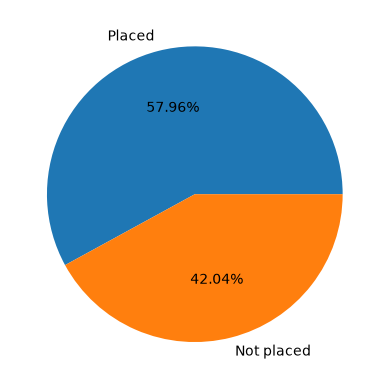

In [30]:
import matplotlib.pyplot as plt 
total_students_Notplaced=total_students_applied - total_students_placed
values=[total_students_placed ,total_students_Notplaced ]
labels=["Placed" , "Not placed "]
plt.pie(values , labels=labels , autopct="%1.2f%%")
plt.show()




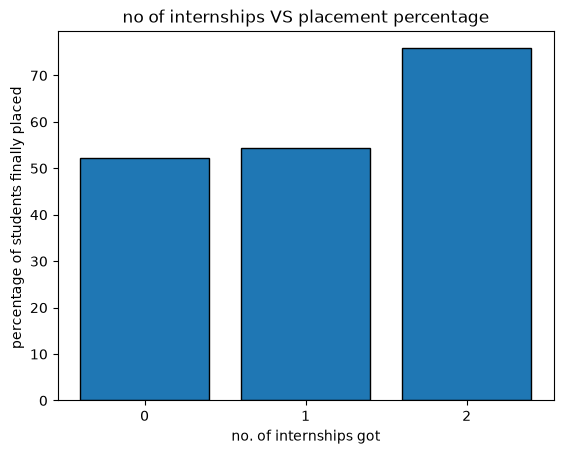

In [43]:

plt.bar(comparision["interns"] ,comparision["placement_percentage"] , edgecolor="black" )
plt.xticks(comparision["interns"] )
plt.xlabel("no. of internships got")
plt.ylabel("percentage of students finally placed ")
plt.title("no of internships VS placement percentage")
plt.show()


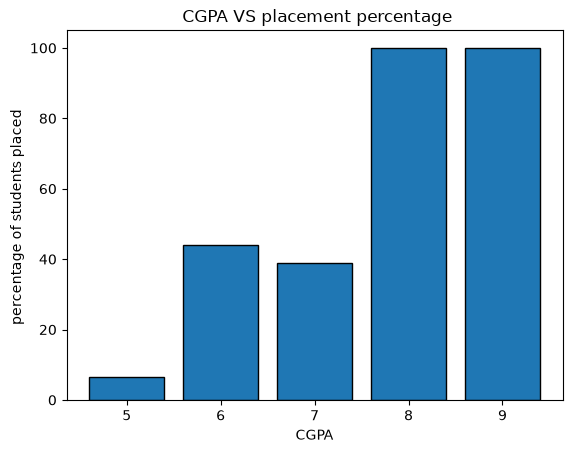

In [44]:

plt.bar(comparision2["CGPA"] ,comparision2["placement percentage"] , edgecolor="black" )
plt.xticks(comparision2["CGPA"] )
plt.xlabel("CGPA")
plt.ylabel("percentage of students placed ")
plt.title(" CGPA VS placement percentage")
plt.show()